# SPVM FIGURES
This notebook contains the figures I will be using in my poster in spvm


# n(t) vs t 
Figure 2 in the second paper

In [ ]:
# 1. Define the 3-parameter function
def logistic_model(t, N_0, k, t_0):
    return N_0 / (1 + np.exp(-k * (t - t_0)))




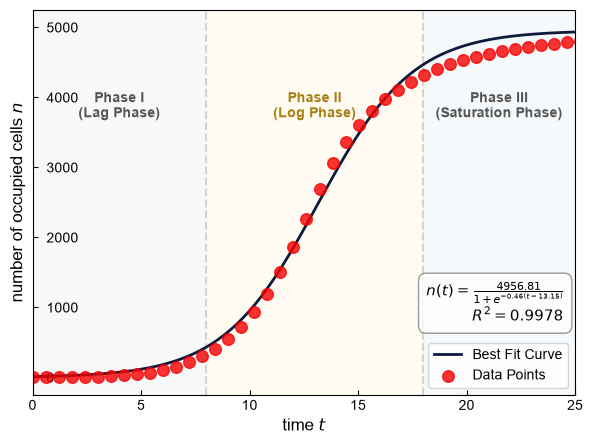

In [129]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

color2 = "#ECB00A"
color1 = "#0d1a3c"


# 1. Define the logistic model function
def logistic_model(t, N_0, k, t_0):
    return N_0 / (1 + np.exp(-k * (t - t_0)))


N = 150

# 2. Load data from the .dat file
data = np.loadtxt("original,average_n_vs_t,sims=500,k=0.60,H=0.02.dat")

# Extract columns
y_data = data[:, 0]  # number of occupied sites
t_data = data[:, 1]  # x-axis represents independent variable 't'

# Clean NaNs
mask = ~np.isnan(t_data) & ~np.isnan(y_data)
y_data = y_data[mask]
t_data = t_data[mask]

# Sort data by time (required for np.interp to work reliably)
sort_indices = np.argsort(t_data)
t_data = t_data[sort_indices]
y_data = y_data[sort_indices]

# Resample onto uniform time grid
t_uniform = np.linspace(t_data.min(), t_data.max(), N)
y_uniform = np.interp(t_uniform, t_data, y_data)

initial_guesses = [max(y_uniform), 1.0, np.median(t_uniform)]

# --- Perform the curve fit ---
popt, pcov = curve_fit(
    logistic_model, t_uniform, y_uniform, p0=initial_guesses
)

# Unpack fitted parameters
N_0_opt, k_opt, t_0_opt = popt

# 4. Calculate R^2 (Coefficient of Determination)
y_pred = logistic_model(t_uniform, *popt)
ss_res = np.sum((y_uniform - y_pred) ** 2)
ss_tot = np.sum((y_uniform - np.mean(y_uniform)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# 5. Generate smooth curves for plotting
t_fit = np.linspace(min(t_data), max(t_data), 500)
y_fit = logistic_model(t_fit, *popt)

# 6. Formatting & Font Configuration
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = (
    "dejavusans"  # Clean fallback math font if needed
)

# Create the figure
fig, ax = plt.subplots(figsize=(7, 5))

phase1_end = 8
phase2_end = 18
plot_xmax = 25
text_height_ratio = 0.75

# Add shaded background regions (zorder=0 to keep them behind data)
ax.axvspan(0, phase1_end, color="#f4f4f6", alpha=0.6, zorder=0)  # Light grey
ax.axvspan(
    phase1_end, phase2_end, color="#fff9e6", alpha=0.5, zorder=0
)  # Soft yellow
ax.axvspan(
    phase2_end, plot_xmax, color="#f1f6f9", alpha=0.6, zorder=0
)  # Soft blue/grey

# Add text labels tracking data coordinates horizontally and axes fractions vertically
ax.text(
    (0 + phase1_end) / 2,
    text_height_ratio,
    "Phase I\n(Lag Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#555555",
    zorder=3,
)
ax.text(
    (phase1_end + phase2_end) / 2,
    text_height_ratio,
    "Phase II\n(Log Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#A77F12",
    zorder=3,
)
ax.text(
    (phase2_end + plot_xmax) / 2,
    text_height_ratio,
    "Phase III\n(Saturation Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#555555",
    zorder=3,
)

# Subtle vertical dashed lines at boundaries
ax.axvline(phase1_end, color="gray", linestyle="--", alpha=0.3, zorder=1)
ax.axvline(phase2_end, color="gray", linestyle="--", alpha=0.3, zorder=1)

# Plot the raw uniform data and fitted curve
ax.plot(t_fit, y_fit, color=color1, linewidth=2, label="Best Fit Curve", zorder=1)
ax.scatter(
    t_uniform,
    y_uniform,
    s=70,
    marker="o",
    color="#F70000",
    alpha=0.8,
    label="Data Points",
    zorder=2,
)

# 7. Display fitted equation on plot
equation_text = (
    f"$n(t) = \\frac{{{N_0_opt:.2f}}}{{1 + e^{{-{k_opt:.2f}(t - {t_0_opt:.2f})}}}}$\n"
    f"$R^2 = {r_squared:.4f}$"
)

ax.text(
    0.98,
    0.18,  # x near right edge, y elevated safely above the legend box
    equation_text,
    transform=ax.transAxes,
    fontsize=11,
    horizontalalignment="right",  # Right-align the text box boundaries
    verticalalignment="bottom",  # Push text upwards from its coordinate floor
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=0.8
    ),
    zorder=5,
)

# 8. Adjust ticks and labels to point and align INSIDE
ax.tick_params(axis="both", which="both", direction="in")
ax.tick_params(
    axis="y", pad=-10
)  # Pulls the tick scale numbers inside the plot area

# Format alignment for the Y-axis tick labels so they read neatly inside
for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")

# Axis titles
ax.set_xlabel(r"time $\mathit{t}$", fontsize=12)
ax.set_ylabel(r"number of occupied cells $\mathit{n}$", fontsize=12)

# --- FIXED LEGEND CALL ---
ax.legend(
    loc="lower right"
)

ax.set_xlim(0, plot_xmax)

plt.savefig(
    "logistic_growth_phases.png",
    dpi=300,
    transparent=False,
    bbox_inches="tight",
)

plt.show()


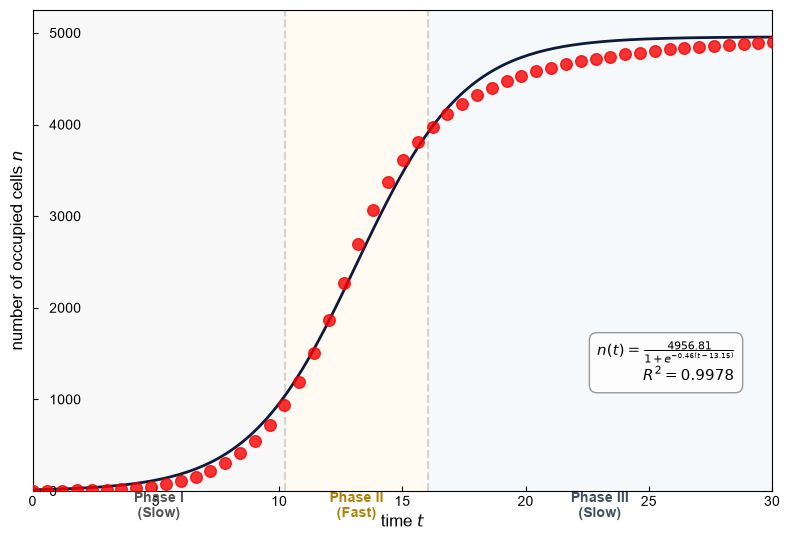

In [98]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

color2 = "#ECB00A"
color1 = "#0d1a3c"


# 1. Define the logistic model function
def logistic_model(t, N_0, k, t_0):
    return N_0 / (1 + np.exp(-k * (t - t_0)))


N = 150

# 2. Load data from the .dat file
data = np.loadtxt("original,average_n_vs_t,sims=500,k=0.60,H=0.02.dat")

# Extract columns
y_data = data[:, 0]  # number of occupied sites
t_data = data[:, 1]  # x-axis represents independent variable 't'

# Clean NaNs
mask = ~np.isnan(t_data) & ~np.isnan(y_data)
y_data = y_data[mask]
t_data = t_data[mask]

# Sort data by time (required for np.interp to work reliably)
sort_indices = np.argsort(t_data)
t_data = t_data[sort_indices]
y_data = y_data[sort_indices]

# Resample onto uniform time grid
t_uniform = np.linspace(t_data.min(), t_data.max(), N)
y_uniform = np.interp(t_uniform, t_data, y_data)

initial_guesses = [max(y_uniform), 1.0, np.median(t_uniform)]

# --- Perform the curve fit to define popt ---
popt, pcov = curve_fit(
    logistic_model, t_uniform, y_uniform, p0=initial_guesses
)

# Unpack fitted parameters
N_0_opt, k_opt, t_0_opt = popt

# 4. Calculate R^2 (Coefficient of Determination)
y_pred = logistic_model(t_uniform, *popt)
ss_res = np.sum((y_uniform - y_pred) ** 2)
ss_tot = np.sum((y_uniform - np.mean(y_uniform)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# 5. Generate smooth curves for plotting
t_fit = np.linspace(min(t_data), max(t_data), 500)
y_fit = logistic_model(t_fit, *popt)

# 6. Formatting & Font Configuration
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "dejavusans"

# Create the figure
fig, ax = plt.subplots(figsize=(8, 5.5))  # Slightly wider for 3 regions

# =========================================================================
# NEW: Calculate phase transition boundaries based on logistic properties
# =========================================================================
delta_t = np.log(2 + np.sqrt(3)) / k_opt  # Distance from center to transition point
phase1_end = t_0_opt - delta_t
phase2_end = t_0_opt + delta_t

# Add shaded background regions (zorder=0 to keep them behind data)
ax.axvspan(0, phase1_end, color="#f4f4f6", alpha=0.6, zorder=0)  # Light grey
ax.axvspan(
    phase1_end, phase2_end, color="#fff9e6", alpha=0.5, zorder=0
)  # Soft yellow
ax.axvspan(
    phase2_end, 30, color="#f1f6f9", alpha=0.6, zorder=0
)  # Soft blue/grey

# Add text labels for the three phases at the top of the chart
text_y = 0.93  # Vertical placement near the top (in axes coordinates)
ax.text(
    phase1_end / 2,
    text_y,
    "Phase I\n(Slow)",
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#555555",
)
ax.text(
    (phase1_end + phase2_end) / 2,
    text_y,
    "Phase II\n(Fast)",
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#b08000",
)
ax.text(
    (phase2_end + 30) / 2,
    text_y,
    "Phase III\n(Slow)",
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#405060",
)

# Optional: Add subtle vertical dashed lines at boundaries
ax.axvline(phase1_end, color="gray", linestyle="--", alpha=0.3, zorder=1)
ax.axvline(phase2_end, color="gray", linestyle="--", alpha=0.3, zorder=1)
# =========================================================================

# Plot the raw uniform data and fitted curve
ax.plot(t_fit, y_fit, color=color1, linewidth=2, label="Best Fit Curve", zorder=3)
ax.scatter(
    t_uniform,
    y_uniform,
    s=70,
    marker="o",
    color="#F70000",
    alpha=0.8,
    label="Data Points",
    zorder=4,
)

# 7. Display fitted equation on plot
equation_text = (
    f"$n(t) = \\frac{{{N_0_opt:.2f}}}{{1 + e^{{-{k_opt:.2f}(t - {t_0_opt:.2f})}}}}$\n"
    f"$R^2 = {r_squared:.4f}$"
)

# Shifted x slightly left (0.95) to ensure it doesn't clip the right edge
ax.text(
    0.95,
    0.22,
    equation_text,
    transform=ax.transAxes,
    fontsize=11,
    horizontalalignment="right",
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=0.8
    ),
    zorder=5,
)

# 8. Adjust ticks and labels to point and align INSIDE
ax.tick_params(axis="both", which="both", direction="in")
ax.tick_params(axis="y", pad=-12)

for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")

# Bold the X and Y Axis titles
ax.set_xlabel(r"time $\mathit{t}$", fontsize=12)
ax.set_ylabel(r"number of occupied cells $\mathit{n}$", fontsize=12)

# Finalize layout
ax.set_xlim(0, 30)
ax.set_ylim(0, max(y_uniform) * 1.05)  # Add breathing room at top for labels

plt.tight_layout()
plt.show()
